# Model 2 — CNN from scratch
A conventional 10-conv-layer CNN with no pretraining. This is the baseline: how far does a plain CNN get on fundus images without ImageNet features or attention?

Same dataset split, class order, class weights, focal loss (α=0.25, γ=2), Adam-style optimiser with ReduceLROnPlateau + early stopping on val loss, and the same test metrics as the Attention U-Net, so the comparison is like-for-like.

In [1]:
import os, sys, json, time
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, torch, torch.nn as nn
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
sys.path.insert(0, os.getcwd())          # common.py sits next to this notebook
from common import *

DATASET_PATH = r"C:\Users\pooja\Desktop\dp\Diabetic Retenopathy.v8i.folder.new_updated"
OUT_DIR      = r"C:\Users\pooja\Desktop\dp\model_comparison"
RUN_DIR      = os.path.join(OUT_DIR, "cnn_scratch"); os.makedirs(RUN_DIR, exist_ok=True)
CFG = {
    "batch_size": 32,
    "focal_alpha": 0.25,
    "focal_gamma": 2.0,
    "reduce_lr_patience": 3,
    "early_stopping_patience": 8,
    "epochs": 40,
    "lr": 0.001,
    "weight_decay": 0.0001
}

seed_all(42)
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

torch 2.11.0+cu128 | NVIDIA GeForce RTX 5070 Ti Laptop GPU


<!-- theory -->
## Theory — data pipeline and augmentation
* **Input normalisation.** Pixels are scaled to $[0,1]$ and then standardised per channel, $x' = (x-\mu)/\sigma$ with the ImageNet statistics $\mu=(0.485,0.456,0.406)$, $\sigma=(0.229,0.224,0.225)$. Pretrained weights were learned on inputs with exactly this distribution.
* **Data augmentation** creates new, realistic training views and reduces over-fitting. A fundus image has no fixed orientation, so random **rotation (±30°), flips, shift (±10%), zoom (±15%)** and **brightness/contrast** jitter keep the diagnosis unchanged while changing the pixels.
* Augmentation is implemented as a random **affine transform** applied on the GPU: for each image a matrix
$$\theta = \begin{bmatrix} \tfrac{\cos a}{s}f_x & -\tfrac{\sin a}{s} & t_x \\ \tfrac{\sin a}{s} & \tfrac{\cos a}{s}f_y & t_y \end{bmatrix}$$
(angle $a$, scale $s$, flips $f_x,f_y=\pm1$, shift $t$) is turned into a sampling grid (`affine_grid`) and the image is resampled bilinearly (`grid_sample`).
* All 17k images are kept in RAM as `uint8` (≈2.5 GB), so each batch is just an index lookup — no disk reads during training.


In [2]:
print("Loading images (uint8, kept in RAM)...")
t = time.time()
data = {s: load_split(DATASET_PATH, s) for s in ["train", "validation", "test"]}
print(f"done in {time.time()-t:.0f}s")

Loading images (uint8, kept in RAM)...
  train     :  12716 images  [1206, 3304, 6499, 1020, 687]
  validation:   1696 images  [161, 441, 867, 136, 91]
  test      :   2544 images  [241, 661, 1300, 204, 138]
done in 19s


<!-- theory -->
## Theory — Convolutional Neural Networks
**Convolution.** A $3\times3$ filter $W$ slides over the image and computes, at every position, a weighted sum of the neighbourhood:
$$y_{i,j,k} = b_k + \sum_{u,v,c} W_{u,v,c,k}\; x_{i+u,\,j+v,\,c}$$
The same filter is reused everywhere (**weight sharing**), so a filter that detects a red dot detects it anywhere in the retina (**translation equivariance**).

**Building blocks of each stage**
| Layer | Role |
|---|---|
| Conv 3×3 | learns local patterns (edges → blobs → lesions) |
| **BatchNorm** | normalises activations per channel: $\hat x = \frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}},\ y=\gamma\hat x+\beta$ — stabilises and speeds up training |
| **ReLU** | non-linearity $\max(0,x)$ |
| **MaxPool 2×2** | halves resolution, keeps the strongest response, adds small shift invariance |

**Receptive field.** Two stacked 3×3 convs see a 5×5 region with fewer weights than one 5×5 conv (VGG idea). After 5 stages (10 convs + 5 pools) each output unit "sees" most of the 224×224 image, but information from distant regions is combined only in the deepest layers.

**Global Average Pooling** averages each 7×7 feature map into one number, replacing a huge fully-connected layer and reducing over-fitting.

**Parameter count** of a conv layer: $k^2 \cdot C_{in}\cdot C_{out}$. Stage 5 (512→512) dominates: $9\cdot512\cdot512 \approx 2.4$ M per conv — 3.54 M of the model's 4.85 M parameters.

**Why train from scratch?** This is the *baseline*: no ImageNet knowledge and no attention, so it shows how much transfer learning and attention add.


In [3]:
class SimpleCNN(nn.Module):
    """Plain CNN trained from scratch: 5 x (Conv-BN-ReLU x2 + MaxPool) -> GAP -> MLP head."""
    def __init__(self, n_classes=5, widths=(32, 64, 128, 256, 512), dropout=0.5):
        super().__init__()
        layers, c_in = [], 3
        for w in widths:
            layers += [nn.Conv2d(c_in, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True),
                       nn.Conv2d(w, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True),
                       nn.MaxPool2d(2)]
            c_in = w
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout),
                                  nn.Linear(c_in, 256), nn.ReLU(inplace=True), nn.Dropout(dropout * 0.6),
                                  nn.Linear(256, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def build_model():
    return SimpleCNN()
model = build_model().to(device).to(memory_format=torch.channels_last)
n_params = sum(p.numel() for p in model.parameters())
print(model.__class__.__name__, f"{n_params:,} parameters")

SimpleCNN 4,846,821 parameters


<!-- theory -->
## Theory — handling class imbalance
**Class weights.** With $N$ training images, $K=5$ classes and $n_c$ images of class $c$, the "balanced" weight is
$$w_c = \frac{N}{K\,n_c}$$
so rare grades (Severe ≈ 3.7) count much more than No_DR (≈ 0.39).

**Focal loss** (Lin et al., 2017). Cross-entropy is $-\log p_t$, where $p_t$ is the predicted probability of the true class. Focal loss adds a modulating factor:
$$FL(p_t) = -\,w_c\,\alpha\,(1-p_t)^{\gamma}\,\log p_t,\qquad \alpha = 0.25,\ \gamma = 2$$
When an image is already classified confidently ($p_t \to 1$), $(1-p_t)^\gamma \to 0$ and its loss nearly vanishes, so the gradient concentrates on hard and minority examples.

| $p_t$ | Cross-entropy | Focal factor $(1-p_t)^2$ |
|---|---|---|
| 0.9 (easy) | 0.105 | 0.01 → loss shrinks 100× |
| 0.5 | 0.693 | 0.25 |
| 0.1 (hard) | 2.303 | 0.81 → almost full loss |


## Theory — optimisation
* **Gradient descent with Adam / AdamW.** Adam keeps running averages of the gradient $m_t$ and squared gradient $v_t$ and updates $\theta \leftarrow \theta - \eta\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$. **AdamW** applies weight decay $\lambda\theta$ separately from the adaptive step, which regularises better.
* **ReduceLROnPlateau** halves the learning rate $\eta$ when the validation loss stops improving, letting the model settle into a minimum.
* **Early stopping + checkpointing** keeps the weights with the lowest validation loss — protection against over-fitting.
* **Mixed precision (FP16)** runs matrix multiplications in half precision on tensor cores (≈2× faster); a *gradient scaler* multiplies the loss before back-propagation so small gradients do not underflow.
* **Gradient clipping** (norm 1.0) prevents occasional exploding updates.
* **Batch / epoch:** one *step* uses a mini-batch of 32 images; one *epoch* is a full pass over the 12,716 training images.


In [4]:
history, train_time_s, cw = train(model, data, CFG, device, os.path.join(RUN_DIR, "best_model.pt"))
print(f"Training time: {train_time_s/60:.1f} min | class weights: {np.round(cw, 3)}")

Epoch  1/40  loss 0.2530  acc 0.3319 | val_loss 0.2689  val_acc 0.3927  val_bal_acc 0.2804  lr 1.0e-03  [101s]  * saved
Epoch  2/40  loss 0.2343  acc 0.4341 | val_loss 0.2372  val_acc 0.2889  val_bal_acc 0.2729  lr 1.0e-03  [187s]  * saved
Epoch  3/40  loss 0.2287  acc 0.4606 | val_loss 0.2276  val_acc 0.4080  val_bal_acc 0.3004  lr 1.0e-03  [273s]  * saved
Epoch  4/40  loss 0.2231  acc 0.4880 | val_loss 0.2190  val_acc 0.5407  val_bal_acc 0.3271  lr 1.0e-03  [359s]  * saved
Epoch  5/40  loss 0.2179  acc 0.4930 | val_loss 0.1991  val_acc 0.5395  val_bal_acc 0.3592  lr 1.0e-03  [446s]  * saved
Epoch  6/40  loss 0.2141  acc 0.5090 | val_loss 0.1930  val_acc 0.5554  val_bal_acc 0.3960  lr 1.0e-03  [533s]  * saved
Epoch  7/40  loss 0.2025  acc 0.5187 | val_loss 0.1860  val_acc 0.5991  val_bal_acc 0.4334  lr 1.0e-03  [620s]  * saved
Epoch  8/40  loss 0.1909  acc 0.5377 | val_loss 0.1681  val_acc 0.5466  val_bal_acc 0.4725  lr 1.0e-03  [707s]  * saved
Epoch  9/40  loss 0.1821  acc 0.5649 | v

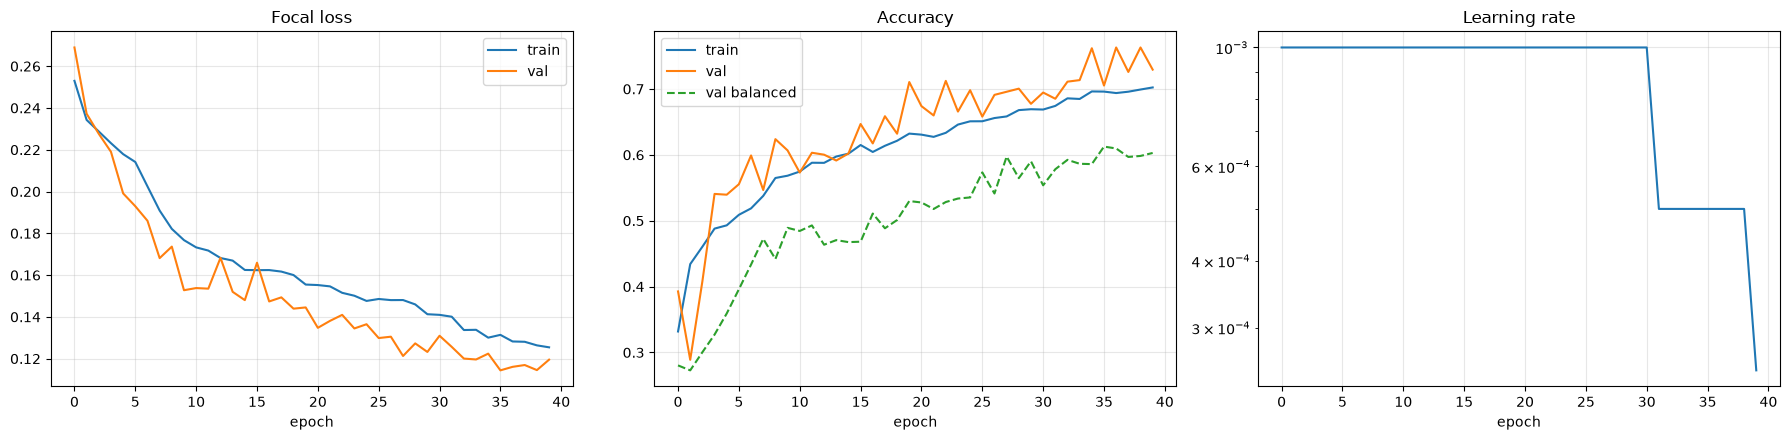

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(history["loss"], label="train"); ax[0].plot(history["val_loss"], label="val"); ax[0].set_title("Focal loss")
ax[1].plot(history["accuracy"], label="train"); ax[1].plot(history["val_accuracy"], label="val"); ax[1].set_title("Accuracy")
ax[1].plot(history["val_balanced_accuracy"], label="val balanced", ls="--")
ax[2].plot(history["lr"]); ax[2].set_yscale("log"); ax[2].set_title("Learning rate")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[0].legend(); ax[1].legend(); plt.tight_layout()
plt.savefig(os.path.join(RUN_DIR, "training_history.png"), dpi=200); plt.show()

<!-- theory -->
## Theory — evaluation metrics
The test set is imbalanced (51% No_DR), so several metrics are reported:

| Metric | Formula / meaning |
|---|---|
| **Accuracy** | $\frac{\#\text{correct}}{N}$ — dominated by the majority class |
| **Recall (sensitivity)** of class $c$ | $\frac{TP_c}{TP_c + FN_c}$ — fraction of class-$c$ images found |
| **Precision** of class $c$ | $\frac{TP_c}{TP_c + FP_c}$ — fraction of class-$c$ predictions that are right |
| **F1** | $\frac{2PR}{P+R}$; **macro-F1** averages it over the 5 classes |
| **Balanced accuracy** | $\frac{1}{K}\sum_c \text{Recall}_c$ — every grade counts equally (headline metric) |
| **Cohen's kappa** | $\kappa = \frac{p_o - p_e}{1 - p_e}$ — agreement beyond chance ($p_o$ observed, $p_e$ expected by chance) |
| **ROC-AUC** (one-vs-rest) | area under TPR-vs-FPR curve for each class; 0.5 = random, 1 = perfect |

The **confusion matrix** $M_{ij}$ counts images of true class $i$ predicted as class $j$; the diagonal holds correct predictions and the off-diagonal cells show *which* grades get confused.


                precision    recall  f1-score   support

          Mild     0.3928    0.8133    0.5297       241
      Moderate     0.7804    0.3011    0.4345       661
         No_DR     0.9641    0.9723    0.9682      1300
Proliferate_DR     0.5086    0.4363    0.4697       204
        Severe     0.2566    0.5652    0.3529       138

      accuracy                         0.7178      2544
     macro avg     0.5805    0.6176    0.5510      2544
  weighted avg     0.7874    0.7178    0.7146      2544

{'accuracy': 0.7178, 'balanced_accuracy': 0.6176, 'kappa': 0.585, 'quadratic_kappa': 0.4453, 'macro_f1': 0.551, 'macro_auc': 0.919}
saved -> C:\Users\pooja\Desktop\dp\model_comparison\results\cnn_scratch.json


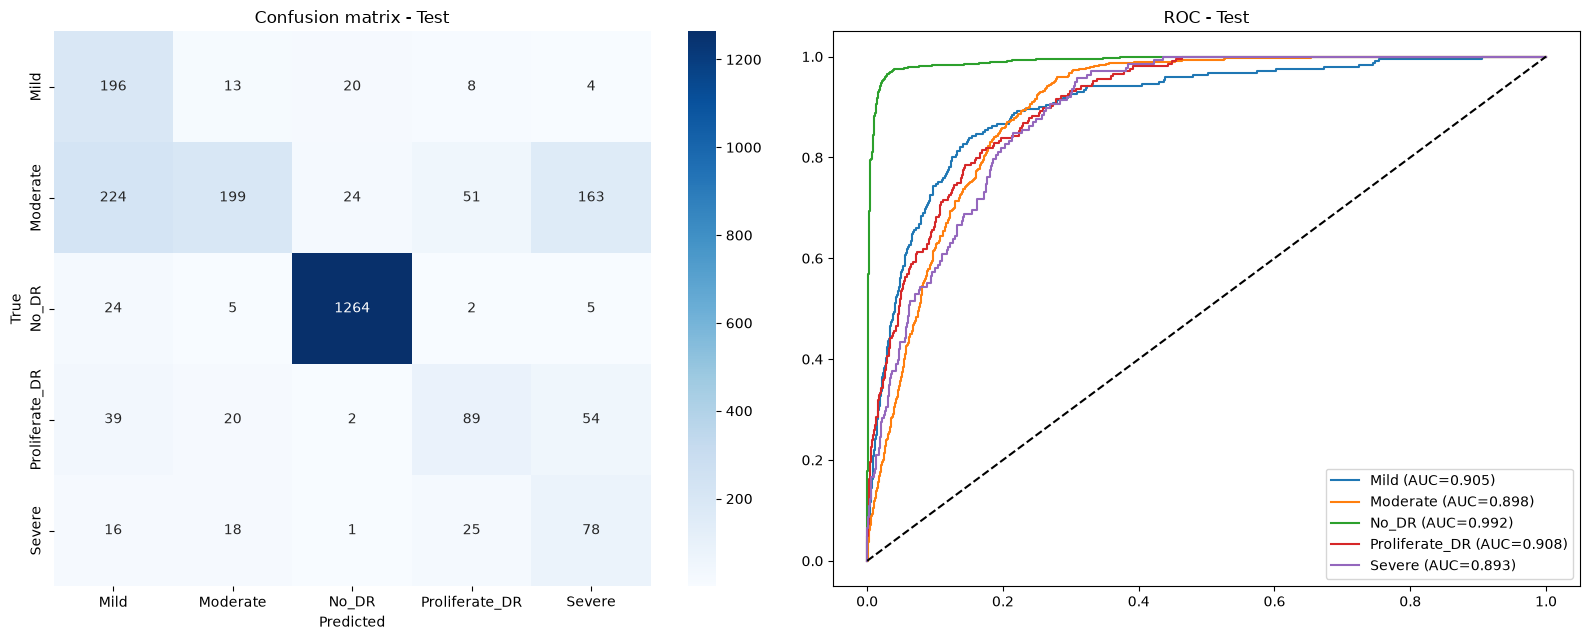

In [6]:
xte, yte = data["test"]
prob = predict(model, xte, device)
y = yte.numpy()
res = save_results(os.path.join(OUT_DIR, "results", "cnn_scratch.json"), "CNN (scratch)", y, prob, {
    "params": n_params, "epochs_trained": len(history["loss"]), "train_time_s": train_time_s,
    "inference_ms_per_img": inference_ms(model, device), "framework": f"PyTorch {torch.__version__}",
    "history": history})

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
cm = confusion_matrix(y, prob.argmax(1))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
ax[0].set_title("Confusion matrix - Test"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
for i, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y == i, prob[:, i]); ax[1].plot(fpr, tpr, label=f"{c} (AUC={roc_auc_score(y == i, prob[:, i]):.3f})")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].legend(loc="lower right"); ax[1].set_title("ROC - Test")
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "test_cm_roc.png"), dpi=200); plt.show()